In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
import shap

In [ ]:
DATA_FILE = Path("data/forecast_dataset.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError("Expected input file: data/forecast_dataset.csv")
SEED = 42
plt.rcParams["figure.figsize"] = (11, 4)
print("Python:", sys.version.split()[0])


In [3]:
demand = pd.read_csv(DATA_FILE)
demand["timestamp_utc"] = pd.to_datetime(demand["timestamp_utc"], utc=True)
demand = demand.sort_values("timestamp_utc")


In [4]:
assert demand["timestamp_utc"].is_unique
assert demand.notna().all().all()
assert demand["electricity_kwh"].ge(0).all()
assert demand["timestamp_utc"].diff().dropna().eq(pd.Timedelta(minutes=30)).all()

/var/folders/4f/jv86nkc567qcj7jsnqvbv_hw0000gn/T/ipykernel_5279/864561786.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert demand["timestamp_utc"].diff().dropna().eq(pd.Timedelta(minutes=30)).all()


In [5]:
local = demand.set_index("timestamp_utc")["electricity_kwh"].tz_convert("Pacific/Auckland")
assert (local.index.strftime("%Y-%m-%d") == demand["trading_date"].to_numpy()).all()

In [6]:
daily = local.resample("D").sum(min_count=1).div(1_000_000).to_frame("energy_gwh")

In [7]:
counts = local.resample("D").count()
next_midnights = pd.date_range(daily.index[0], periods=len(daily) + 1, freq="D")
expected = np.diff(next_midnights.tz_convert("UTC").asi8) / pd.Timedelta(minutes=30).value
assert np.array_equal(counts.to_numpy(), expected)

/var/folders/4f/jv86nkc567qcj7jsnqvbv_hw0000gn/T/ipykernel_5279/3933239734.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  expected = np.diff(next_midnights.tz_convert("UTC").asi8) / pd.Timedelta(minutes=30).value


In [8]:
daily.index = daily.index.tz_localize(None)
daily.index.name = "date"
assert daily.index.equals(pd.date_range("2023-01-01", "2025-12-31", name="date"))

In [9]:
print(f"{len(demand):,} half-hourly rows; {len(daily):,} complete local days")
print("Half-hours per day:", counts.value_counts().sort_index().to_dict())
display(daily.head())
display(daily.describe().round(3))

52,608 half-hourly rows; 1,096 complete local days
Half-hours per day: {46: 3, 48: 1090, 50: 3}


,energy_gwh
date,
2023-01-01,17.201909
2023-01-02,17.739815
2023-01-03,18.444816
2023-01-04,20.399108
2023-01-05,21.093127


,energy_gwh
count,1096.000
mean,24.696
std,3.073
min,17.202
25%,22.840
50%,24.375
75%,26.548
max,33.203


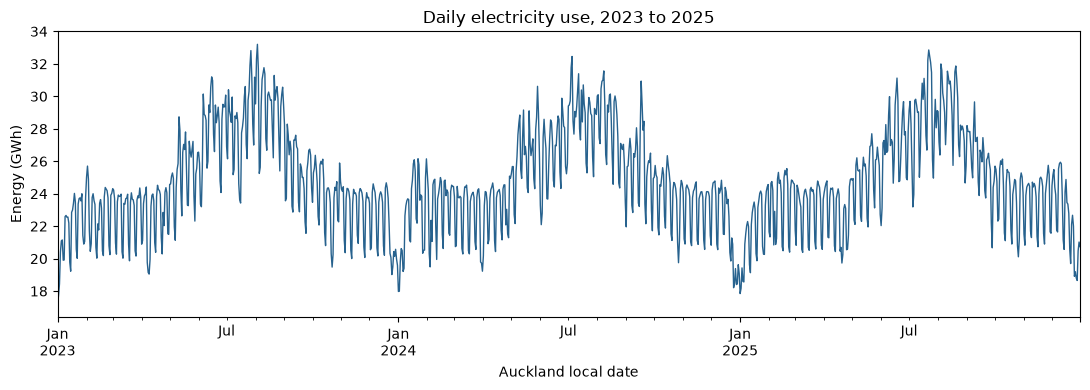

In [10]:
ax = daily["energy_gwh"].plot(color="#27628e", linewidth=1)
ax.set(title="Daily electricity use, 2023 to 2025", xlabel="Auckland local date", ylabel="Energy (GWh)")
plt.tight_layout()
plt.show()

In [11]:
features = pd.DataFrame(index=daily.index)
features["previous_day"] = daily["energy_gwh"].shift(1)
features["previous_week"] = daily["energy_gwh"].shift(7)
features["previous_7_day_mean"] = daily["energy_gwh"].shift(1).rolling(7).mean()

In [12]:
features["weekday"] = pd.Categorical(daily.index.dayofweek, categories=range(7))
features["month"] = pd.Categorical(daily.index.month, categories=range(1, 13))
features = pd.get_dummies(features, columns=["weekday", "month"], drop_first=True, dtype=float)

In [13]:
model_data = features.join(daily).dropna()
X = model_data.drop(columns="energy_gwh")
y = model_data["energy_gwh"]
assert np.allclose(X["previous_7_day_mean"], daily["energy_gwh"].shift(1).rolling(7).mean().loc[X.index])
display(model_data.head().round(3))

,previous_day,previous_week,previous_7_day_mean,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,month_2,...,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,energy_gwh
date,,,,,,,,,,,,,,,,,,,,,
2023-01-08,19.904,17.202,19.419,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.919
2023-01-09,19.919,17.740,19.807,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.591
2023-01-10,22.591,18.445,20.500,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.661
2023-01-11,22.661,20.399,21.103,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.549
2023-01-12,22.549,21.093,21.410,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.563


In [14]:
TRAIN_END = "2024-12-31"
VALIDATION_END = "2025-05-27"
train = X.index <= TRAIN_END
valid = (X.index > TRAIN_END) & (X.index <= VALIDATION_END)
test = X.index > VALIDATION_END
X_train, y_train = X.loc[train], y.loc[train]
X_valid, y_valid = X.loc[valid], y.loc[valid]
X_test, y_test = X.loc[test], y.loc[test]
assert X_train.index.max() < X_valid.index.min() < X_test.index.min()
assert len(X_train) + len(X_valid) + len(X_test) == len(X)

In [15]:
split_table = pd.DataFrame([
    {"Period": name, "First date": part.index.min().date(), "Last date": part.index.max().date(), "Days": len(part)}
    for name, part in [("Training", X_train), ("Validation", X_valid), ("Test", X_test)]
])
display(split_table)

,Period,First date,Last date,Days
0,Training,2023-01-08,2024-12-31,724
1,Validation,2025-01-01,2025-05-27,147
2,Test,2025-05-28,2025-12-31,218


In [16]:
def score(actual, predicted):
    return {"MAE (GWh)": mean_absolute_error(actual, predicted),
            "RMSE (GWh)": np.sqrt(mean_squared_error(actual, predicted))}

In [17]:
models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=1),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3,
                            objective="reg:squarederror", random_state=SEED, n_jobs=1),
}

In [18]:
validation_scores = {"Seasonal naive": score(y_valid, X_valid["previous_week"])}
fitted = {}
for name, model in models.items():
    fitted[name] = clone(model).fit(X_train, y_train)
    validation_scores[name] = score(y_valid, fitted[name].predict(X_valid))

In [19]:
validation_results = pd.DataFrame(validation_scores).T.sort_values("RMSE (GWh)")
display(validation_results.round(3))

,MAE (GWh),RMSE (GWh)
Linear regression,0.468,0.780
Random forest,0.578,0.889
XGBoost,0.570,0.904
Seasonal naive,0.856,1.288


In [20]:
tree_names = ["Random forest", "XGBoost"]
best_tree = min(tree_names, key=lambda name: validation_scores[name]["RMSE (GWh)"])
if best_tree == "Random forest":
    grid = {"n_estimators": [100, 200], "max_depth": [5, None], "min_samples_leaf": [1, 5]}
else:
    grid = {"n_estimators": [100, 200], "learning_rate": [0.03, 0.1], "max_depth": [2, 3]}

In [21]:
cv = TimeSeriesSplit(n_splits=3, test_size=90)
search = GridSearchCV(clone(models[best_tree]), grid, cv=cv,
                      scoring="neg_mean_squared_error", n_jobs=1)
search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, None], 'min_samples_leaf': [1, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl... test_size=90)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"v

In [22]:
tuned_name = best_tree + " (tuned)"
fitted[tuned_name] = search.best_estimator_
validation_scores[tuned_name] = score(y_valid, search.predict(X_valid))
validation_results = pd.DataFrame(validation_scores).T.sort_values("RMSE (GWh)")
selected_name = validation_results.index[0]

In [23]:
print("Tree model tuned:", best_tree)
print("Best training-CV settings:", search.best_params_)
print("Training-CV root mean MSE:", round(np.sqrt(-search.best_score_), 3), "GWh")
print("Model selected:", selected_name)
display(validation_results.round(3))

Tree model tuned: Random forest
Best training-CV settings: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Training-CV root mean MSE: 1.138 GWh
Model selected: Linear regression


,MAE (GWh),RMSE (GWh)
Linear regression,0.468,0.780
Random forest,0.578,0.889
Random forest (tuned),0.578,0.890
XGBoost,0.570,0.904
Seasonal naive,0.856,1.288


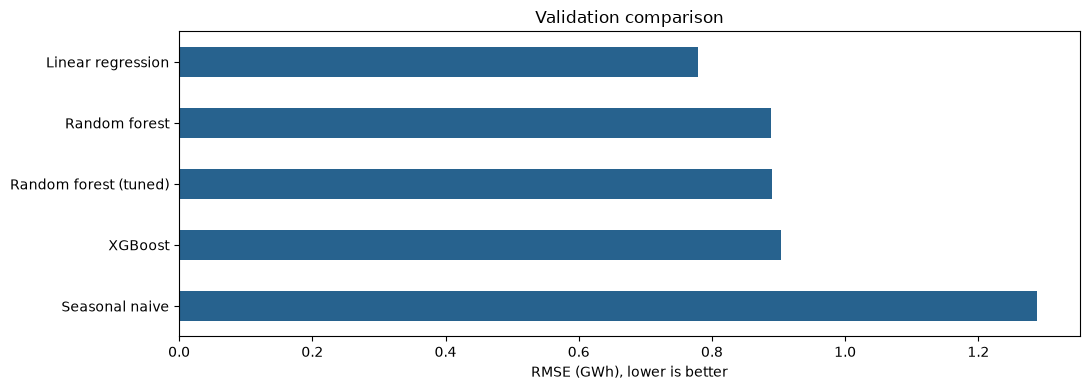

In [24]:
ax = validation_results["RMSE (GWh)"].sort_values().plot.barh(color="#27628e")
ax.set(title="Validation comparison", xlabel="RMSE (GWh), lower is better", ylabel="")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [25]:
explained_name = next(name for name in validation_results.index if name != "Seasonal naive")
explained_model = fitted[explained_name]
background = X_train.sample(n=min(100, len(X_train)), random_state=SEED)
if explained_name == "Linear regression":
    explainer = shap.LinearExplainer(explained_model, background)
else:
    explainer = shap.TreeExplainer(explained_model, data=background)
explanations = explainer(X_valid)

In [26]:
importance = pd.Series(np.abs(explanations.values).mean(axis=0), index=X.columns).sort_values(ascending=False)
print("Model explained:", explained_name)
display(importance.head(6).rename("Mean absolute SHAP (GWh)").to_frame().round(3))

Model explained: Linear regression


,Mean absolute SHAP (GWh)
weekday_5,1.267
previous_day,1.221
weekday_6,0.835
weekday_4,0.455
weekday_3,0.453
weekday_1,0.407


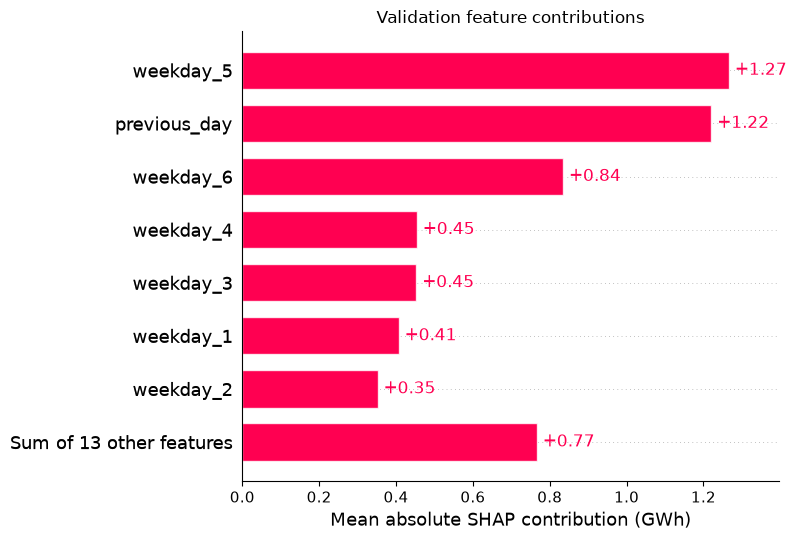

In [27]:
shap.plots.bar(explanations, max_display=8, show=False)
plt.title("Validation feature contributions")
plt.xlabel("Mean absolute SHAP contribution (GWh)")
plt.tight_layout()
plt.show()

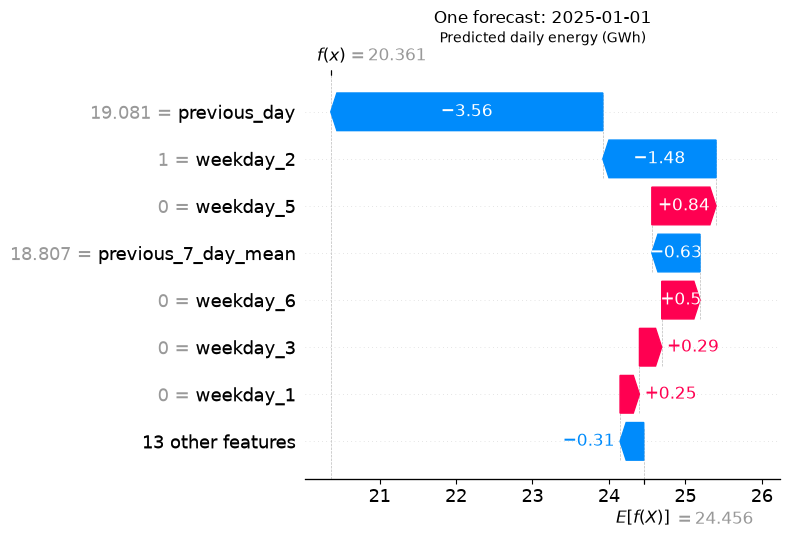

In [28]:
shap.plots.waterfall(explanations[0], max_display=8, show=False)
plt.title(f"One forecast: {X_valid.index[0].date()}")
plt.xlabel("Predicted daily energy (GWh)")
plt.tight_layout()
plt.show()

In [29]:
assert np.allclose(explanations.base_values + explanations.values.sum(axis=1),
                   explained_model.predict(X_valid), atol=1e-5)

In [30]:
if selected_name == "Seasonal naive":
    final_model = None
    prediction = X_test["previous_week"].to_numpy()
else:
    final_model = clone(fitted[selected_name]).fit(X.loc[~test], y.loc[~test])
    prediction = final_model.predict(X_test)

In [31]:
predictions = pd.DataFrame({"actual_gwh": y_test, "forecast_gwh": prediction,
                            "baseline_gwh": X_test["previous_week"]})
test_results = pd.DataFrame({
    "Seasonal naive": score(y_test, predictions["baseline_gwh"]),
    selected_name: score(y_test, predictions["forecast_gwh"]),
}).T

In [32]:
baseline_rmse = test_results.loc["Seasonal naive", "RMSE (GWh)"]
model_rmse = test_results.loc[selected_name, "RMSE (GWh)"]
improvement = 100 * (baseline_rmse - model_rmse) / baseline_rmse
display(test_results.round(3))
print(f"Test RMSE reduction against seasonal naive: {improvement:.1f}%")

,MAE (GWh),RMSE (GWh)
Seasonal naive,1.198,1.614
Linear regression,0.658,0.949


Test RMSE reduction against seasonal naive: 41.2%


In [33]:
monthly = pd.DataFrame([
    {"Month": str(month), "Days": len(part), **score(part.actual_gwh, part.forecast_gwh)}
    for month, part in predictions.groupby(predictions.index.to_period("M"))
]).set_index("Month")
display(monthly.round(3))

,Days,MAE (GWh),RMSE (GWh)
Month,,,
2025-05,4,0.497,0.537
2025-06,30,1.099,1.445
2025-07,31,0.893,1.146
2025-08,31,0.728,1.009
2025-09,30,0.525,0.724
2025-10,31,0.430,0.688
2025-11,30,0.252,0.321
2025-12,31,0.701,0.928


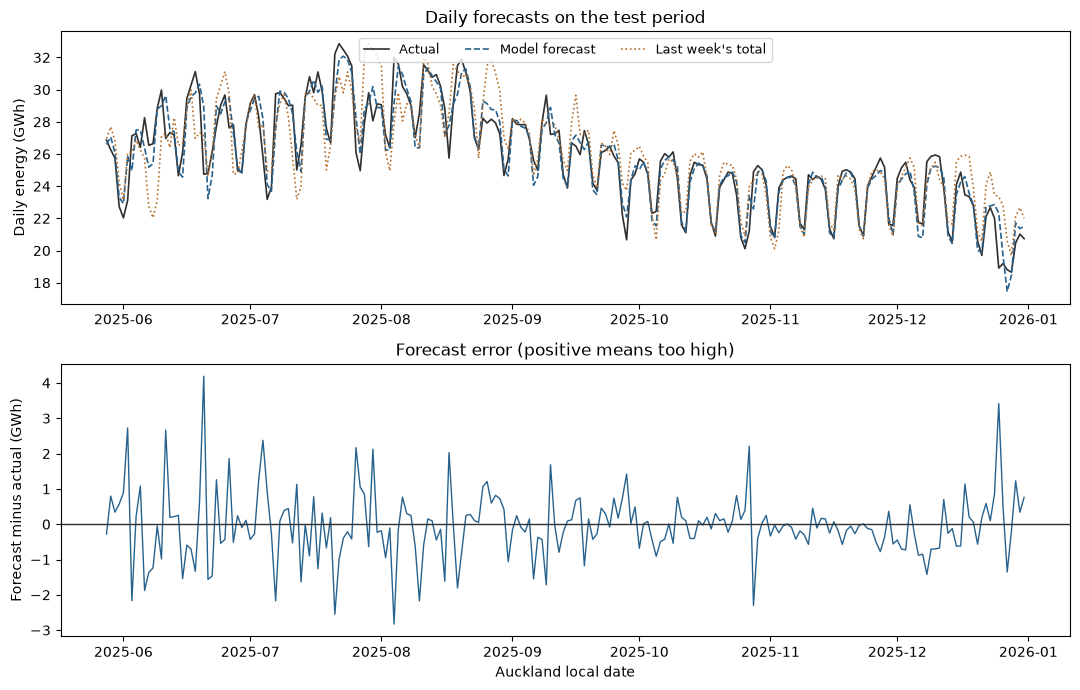

In [34]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for column, label, colour, style in [
    ("actual_gwh", "Actual", "#303030", "-"),
    ("forecast_gwh", "Model forecast", "#27628e", "--"),
    ("baseline_gwh", "Last week's total", "#b66b26", ":"),
]:
    axes[0].plot(predictions.index, predictions[column], label=label, color=colour, linestyle=style, linewidth=1.2)
axes[0].set(title="Daily forecasts on the test period", ylabel="Daily energy (GWh)")
axes[0].legend(ncol=3, loc="upper center", fontsize=9)
error = predictions["forecast_gwh"] - predictions["actual_gwh"]
axes[1].plot(predictions.index, error, color="#27628e", linewidth=1)
axes[1].axhline(0, color="#303030", linewidth=1)
axes[1].set(title="Forecast error (positive means too high)", xlabel="Auckland local date", ylabel="Forecast minus actual (GWh)")
plt.tight_layout()
plt.show()

In [35]:
results_table = pd.concat({
    "Validation": validation_results.loc[[selected_name]],
    "Test": test_results,
}, names=["Period", "Model"])
display(results_table.round(3))
print("Test RMSE reduction (%):", round(improvement, 1))

MAE (GWh)  RMSE (GWh)
Period     Model                                   
Validation Linear regression      0.468       0.780
Test       Seasonal naive         1.198       1.614
           Linear regression      0.658       0.949

Test RMSE reduction (%): 41.2
